In [ ]:
# ===== REVISION SETUP: run first, and again after every restart =====
import os, sys, re, time
from pathlib import Path
import numpy as np, pandas as pd

if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

import tensorflow as tf
proj = Path("/content/drive/MyDrive/MSA_Model2_Project")
REPO = proj / "sp_alternative"
RES = proj / "results"
REV = proj / "revision"; REV.mkdir(exist_ok=True)
os.chdir(REPO); sys.path.insert(0, str(REPO))
from dl_model.data_processing.group_aware_zscore_scaler import GroupAwareScalerZ
from dl_model.config.constants import SOP_SCORE_NAME

scaler = GroupAwareScalerZ(mode="rank", use_global=False)
scaler.load(str(REPO / "dl_model/input/orthomam_model2/scaler_0_mode1_dseq_from_true.pkl"))
model = tf.keras.models.load_model(
    REPO / "dl_model/input/orthomam_model2/regressor_model_0_mode1_dseq_from_true.keras", compile=False)
FEATS = list(scaler.feature_names)

def source_of(code):
    c = str(code).lower()
    if c.startswith("muscle"): return "muscle"
    if c.startswith("prank"): return "prank"
    if c.startswith("bali_phy"): return "baliphy"
    if c.startswith("msa."): return "default"
    return "mafft"

def load(path, fid):   # identical to the main analysis
    df = pd.read_csv(path, low_memory=False)
    df = df.drop(columns=["rf_from_true"], errors="ignore")
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    df["code"] = df["code"].astype(str)
    df = df[df["code"] != fid].copy()
    df["source"] = df["code"].map(source_of)
    df = df[df["source"].isin(["mafft", "prank", "muscle"])]
    return df.reset_index(drop=True)

fam = {"23410": load(REPO / "example_data/features/groups_final/unified_stats_23410.csv", "23410"),
       "126014": load(proj / "126014_features_recovered.csv", "126014")}
for fid in ["SIM01", "SIM02", "SIM03"]:
    fam[fid] = load(proj / "sim_families" / fid / f"{fid}_features.csv", fid)
NEW = ["SIM01", "SIM02", "SIM03"]

def predict_within(pool):
    X = pool[FEATS].copy(); X["code1"] = "pool"
    return model(scaler.transform(X).astype("float32"), training=False).numpy().reshape(-1)

def predict_fixed(pool, ref_sorted):
    C = pool[FEATS].to_numpy(dtype=float); out = np.empty_like(C, dtype=np.float32); n = ref_sorted.shape[0]
    for j in range(C.shape[1]):
        l = np.searchsorted(ref_sorted[:, j], C[:, j], "left")
        r = np.searchsorted(ref_sorted[:, j], C[:, j], "right")
        out[:, j] = (l + r) / 2.0 / n
    return model(out, training=False).numpy().reshape(-1)

S = ["mafft", "prank", "muscle"]; N, REPEATS = 100, 100
conds = {f"C1 only {s}": {s: N} for s in S}
conds["C2 balanced"] = {"mafft": 34, "prank": 33, "muscle": 33}
for d_ in S:
    o = [s for s in S if s != d_]
    conds[f"C3 70% {d_}"] = {d_: 70, o[0]: 15, o[1]: 15}

SOP_COLS = [c for c in fam["23410"].columns
            if re.fullmatch(r"sp_(BLOSUM62|PAM250)_GO_-?\d+(\.\d+)?_GE_-?\d+(\.\d+)?", c)]
if SOP_SCORE_NAME not in SOP_COLS: SOP_COLS.append(SOP_SCORE_NAME)

def pboot(diff, n=5000, seed=0):
    diff = np.asarray(diff, float); r = np.random.default_rng(seed)
    m = r.choice(diff, size=(n, len(diff))).mean(axis=1)
    return diff.mean(), np.quantile(m, 0.025), np.quantile(m, 0.975)

for k, d in fam.items(): print(k, dict(d["source"].value_counts()))
print("SoP settings found:", len(SOP_COLS), SOP_COLS)

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.5.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


23410 {'mafft': np.int64(400), 'muscle': np.int64(400), 'prank': np.int64(400)}
126014 {'mafft': np.int64(400), 'prank': np.int64(400), 'muscle': np.int64(400)}
SIM01 {'mafft': np.int64(400), 'muscle': np.int64(400), 'prank': np.int64(400)}
SIM02 {'mafft': np.int64(400), 'muscle': np.int64(400), 'prank': np.int64(400)}
SIM03 {'mafft': np.int64(400), 'muscle': np.int64(400), 'prank': np.int64(400)}
SoP settings found: 12 ['sp_BLOSUM62_GO_-10_GE_-0.5', 'sp_BLOSUM62_GO_-6_GE_-0.5', 'sp_BLOSUM62_GO_-10_GE_-1', 'sp_BLOSUM62_GO_-6_GE_-1', 'sp_BLOSUM62_GO_-10_GE_-0.2', 'sp_BLOSUM62_GO_-6_GE_-0.2', 'sp_PAM250_GO_-10_GE_-0.5', 'sp_PAM250_GO_-6_GE_-0.5', 'sp_PAM250_GO_-10_GE_-1', 'sp_PAM250_GO_-6_GE_-1', 'sp_PAM250_GO_-10_GE_-0.2', 'sp_PAM250_GO_-6_GE_-0.2']


In [ ]:
rng = np.random.default_rng(2026)      # same seed and order as the paper -> same 3,500 pools
rng_ref = np.random.default_rng(99)    # separate generator, so the pools stay identical
rows = []; t0 = time.time()
for fid, df in fam.items():
    X_all = df[FEATS].to_numpy(dtype=float); src = df["source"].to_numpy()
    refs = {"fixed_all":       np.sort(X_all, axis=0),                      # paper's ruler (1,200)
            "fixed_noprank":   np.sort(X_all[src != "prank"], axis=0),     # realistic ruler (800)
            "fixed_prankonly": np.sort(X_all[src == "prank"], axis=0),     # PRANK-only ruler (400)
            "fixed_mix400":    np.sort(X_all[rng_ref.choice(len(df), 400, replace=False)], axis=0)}  # mixed, same size
    for cname, counts in conds.items():
        for rep in range(REPEATS):
            pool = pd.concat([df[df.source == s].sample(n=k, random_state=int(rng.integers(1e9)))
                              for s, k in counts.items()], ignore_index=True)
            d = pool["dseq_from_true"].to_numpy(dtype=float); best = d.min()
            row = dict(family=fid, condition=cname, rep=rep, oracle=best, random_regret=d.mean() - best,
                       model_regret=d[predict_within(pool).argmin()] - best)
            for name, ref in refs.items():
                row[f"{name}_regret"] = d[predict_fixed(pool, ref).argmin()] - best
            for c in SOP_COLS:
                row[f"sop::{c}"] = d[pool[c].to_numpy().argmax()] - best
            row["sop_regret"] = row[f"sop::{SOP_SCORE_NAME}"]
            rows.append(row)
    print(f"done {fid}  ({(time.time() - t0) / 60:.1f} min)")
res = pd.DataFrame(rows); res.to_csv(REV / "revision_perpool.csv", index=False)

# ---- Self-check: are these the paper's pools? (all three numbers should be 0) ----
old = pd.read_csv(RES / "partA_5families_raw.csv"); old["family"] = old["family"].astype(str)
m = old.merge(res, on=["family", "condition", "rep"], suffixes=("_old", ""))
print("\nSELF-CHECK (should all be 0):",
      "model", round(float(np.abs(m["model_regret_old"] - m["model_regret"]).max()), 8),
      "| fix", round(float(np.abs(m["fixed_regret"] - m["fixed_all_regret"]).max()), 8),
      "| SoP", round(float(np.abs(m["sop_regret_old"] - m["sop_regret"]).max()), 8))

# ---- Mean regret over the 5 datasets ----
cols = ["model_regret", "fixed_all_regret", "fixed_noprank_regret", "sop_regret"]
print("\nMEAN REGRET (5 datasets)")
print(res.groupby(["condition", "family"])[cols].mean().groupby("condition").mean().round(4).to_string())
print("\nPRANK-ONLY, per dataset")
print(res[res.condition == "C1 only prank"].groupby("family")[cols].mean().round(4).to_string())

# ---- Paired bootstrap tests per dataset (positive = second method better) ----
comps = {"realistic fix vs original": ("model_regret", "fixed_noprank_regret"),
         "full fix vs original":      ("model_regret", "fixed_all_regret"),
         "full fix vs SoP":           ("sop_regret", "fixed_all_regret"),
         "realistic fix vs SoP":      ("sop_regret", "fixed_noprank_regret")}
st = []
for (fid, cond), g in res.groupby(["family", "condition"]):
    for name, (a, b) in comps.items():
        mean, lo, hi = pboot(g[a].to_numpy() - g[b].to_numpy())
        st.append(dict(family=fid, condition=cond, comparison=name, mean_diff=mean, lo=lo, hi=hi,
                       better=lo > 0, worse=hi < 0, new=fid in NEW))
st = pd.DataFrame(st); st.to_csv(REV / "revision_stats.csv", index=False)
print("\nSIGNIFICANT, out of 5 datasets [and out of the 3 new ones]")
for name in comps:
    s = st[st.comparison == name]
    t = s.groupby("condition").agg(better=("better", "sum"), worse=("worse", "sum"))
    tn = s[s.new].groupby("condition").agg(better_new=("better", "sum"), worse_new=("worse", "sum"))
    print(f"\n-- {name} --"); print(t.join(tn).to_string())

# ---- One overall interval per condition (pools resampled within each dataset) ----
def strat_ci(g, a, b, n=5000, seed=1):
    r = np.random.default_rng(seed); per = []
    for _, h in g.groupby("family"):
        dd = h[a].to_numpy() - h[b].to_numpy()
        per.append(r.choice(dd, size=(n, len(dd))).mean(axis=1))
    mm = np.mean(per, axis=0)
    point = g.groupby("family").apply(lambda h: (h[a] - h[b]).mean()).mean()
    return point, np.quantile(mm, 0.025), np.quantile(mm, 0.975)
print("\nOVERALL 95% INTERVALS (mean over 5 datasets; positive = second method better)")
for cond in ["C1 only prank", "C3 70% prank", "C2 balanced", "C1 only mafft"]:
    g = res[res.condition == cond]
    for name, (a, b) in comps.items():
        p, lo, hi = strat_ci(g, a, b)
        print(f"{cond:15s} | {name:26s} | {p:+.4f} [{lo:+.4f}, {hi:+.4f}]")
print(f"\nTotal time: {(time.time() - t0) / 60:.1f} min")

done 23410  (2.2 min)
done 126014  (4.4 min)
done SIM01  (6.5 min)
done SIM02  (8.8 min)
done SIM03  (11.0 min)

SELF-CHECK (should all be 0): model 0.0 | fix 0.0 | SoP 0.0

MEAN REGRET (5 datasets)
                model_regret  fixed_all_regret  fixed_noprank_regret  sop_regret
condition                                                                       
C1 only mafft         0.0032            0.0035                0.0041      0.0089
C1 only muscle        0.0037            0.0030                0.0034      0.0045
C1 only prank         0.0300            0.0089                0.0123      0.0101
C2 balanced           0.0041            0.0041                0.0045      0.0057
C3 70% mafft          0.0034            0.0031                0.0034      0.0042
C3 70% muscle         0.0038            0.0035                0.0038      0.0051
C3 70% prank          0.0094            0.0051                0.0062      0.0070

PRANK-ONLY, per dataset
        model_regret  fixed_all_regret  fixed_n

/tmp/ipykernel_723/4019111909.py:67: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  point = g.groupby("family").apply(lambda h: (h[a] - h[b]).mean()).mean()
/tmp/ipykernel_723/4019111909.py:67: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  point = g.groupby("family").apply(lambda h: (h[a] - h[b]).mean()).mean()
/tmp/ipykernel_723/4019111909.py:67: DeprecationWarning: DataFrameGroupBy.apply operated on the gr

C2 balanced     | realistic fix vs SoP       | +0.0011 [+0.0008, +0.0015]
C1 only mafft   | realistic fix vs original  | -0.0009 [-0.0013, -0.0004]
C1 only mafft   | full fix vs original       | -0.0003 [-0.0008, +0.0002]
C1 only mafft   | full fix vs SoP            | +0.0054 [+0.0047, +0.0061]
C1 only mafft   | realistic fix vs SoP       | +0.0048 [+0.0042, +0.0054]

Total time: 11.0 min


/tmp/ipykernel_723/4019111909.py:67: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  point = g.groupby("family").apply(lambda h: (h[a] - h[b]).mean()).mean()
/tmp/ipykernel_723/4019111909.py:67: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  point = g.groupby("family").apply(lambda h: (h[a] - h[b]).mean()).mean()
/tmp/ipykernel_723/4019111909.py:67: DeprecationWarning: DataFrameGroupBy.apply operated on the gr

In [ ]:
rng = np.random.default_rng(2028); rows = []; t0 = time.time()
for fid, df in fam.items():
    X_all = df[FEATS].to_numpy(dtype=float); src = df["source"].to_numpy()
    ref800 = np.sort(X_all[src != "prank"], axis=0)
    P_all, M_all, U_all = (df[df.source == s] for s in ["prank", "mafft", "muscle"])
    for rep in range(100):
        P = P_all.sample(100, random_state=int(rng.integers(1e9))).reset_index(drop=True)
        M = M_all.sample(50, random_state=int(rng.integers(1e9))).reset_index(drop=True)
        U = U_all.sample(50, random_state=int(rng.integers(1e9))).reset_index(drop=True)
        MU = pd.concat([M, U], ignore_index=True)
        ALL = pd.concat([P, M, U], ignore_index=True)
        BAL = pd.concat([P.iloc[:34], M.iloc[:33], U.iloc[:33]], ignore_index=True)
        dP, dA, dB = (x["dseq_from_true"].to_numpy(float) for x in (P, ALL, BAL))
        best = dA.min()                                   # best of everything the user has
        own_ref = np.sort(MU[FEATS].to_numpy(dtype=float), axis=0)
        picks = {
            "A0 PRANK pool, original":            dP[predict_within(P).argmin()],
            "A1 PRANK pool + own ruler (100)":     dP[predict_fixed(P, own_ref).argmin()],
            "A2 PRANK pool + ruler (800)":         dP[predict_fixed(P, ref800).argmin()],
            "S0 PRANK pool, SoP":                  dP[P[SOP_SCORE_NAME].to_numpy().argmax()],
            "B1 all 200 together, original":       dA[predict_within(ALL).argmin()],
            "B2 all 200 together, SoP":            dA[ALL[SOP_SCORE_NAME].to_numpy().argmax()],
            "B3 balanced 100, original":           dB[predict_within(BAL).argmin()],
        }
        rows.append(dict(family=fid, rep=rep, **{k: v - best for k, v in picks.items()}))
    print(f"done {fid} ({(time.time() - t0) / 60:.1f} min)")
opt = pd.DataFrame(rows); opt.to_csv(REV / "revision_fix_vs_mixing.csv", index=False)
keys = [c for c in opt.columns if c not in ("family", "rep")]

print("\nREGRET vs the best of all 200 candidates (lower is better)")
per = opt.groupby("family")[keys].mean()
print(per.round(4).T.to_string())
print("\nMean over 5 datasets:"); print(per.mean().round(4).to_string())

print("\nPAIRED TESTS (positive = the second option is better)")
pairs = [("A2 PRANK pool + ruler (800)", "B1 all 200 together, original"),
         ("A1 PRANK pool + own ruler (100)", "B1 all 200 together, original"),
         ("A2 PRANK pool + ruler (800)", "B3 balanced 100, original"),
         ("S0 PRANK pool, SoP", "B1 all 200 together, original")]
for a, b in pairs:
    better = worse = 0; diffs = []
    for fid, g in opt.groupby("family"):
        m_, lo, hi = pboot(g[a] - g[b]); diffs.append(m_)
        better += lo > 0; worse += hi < 0
    print(f"{a}  ->  {b}: mean {np.mean(diffs):+.4f} | second better in {better}/5, worse in {worse}/5")

done 23410 (0.7 min)
done 126014 (1.3 min)
done SIM01 (2.0 min)
done SIM02 (2.6 min)
done SIM03 (3.3 min)

REGRET vs the best of all 200 candidates (lower is better)
family                           126014   23410   SIM01   SIM02   SIM03
A0 PRANK pool, original          0.0231  0.0720  0.0098  0.0775  0.0090
A1 PRANK pool + own ruler (100)  0.0016  0.0313  0.0138  0.0347  0.0172
A2 PRANK pool + ruler (800)      0.0013  0.0331  0.0129  0.0343  0.0197
S0 PRANK pool, SoP               0.0046  0.0395  0.0032  0.0374  0.0082
B1 all 200 together, original    0.0091  0.0030  0.0112  0.0013  0.0064
B2 all 200 together, SoP         0.0087  0.0045  0.0158  0.0020  0.0068
B3 balanced 100, original        0.0062  0.0048  0.0141  0.0021  0.0067

Mean over 5 datasets:
A0 PRANK pool, original            0.0383
A1 PRANK pool + own ruler (100)    0.0197
A2 PRANK pool + ruler (800)        0.0203
S0 PRANK pool, SoP                 0.0186
B1 all 200 together, original      0.0062
B2 all 200 together, SoP 

(a) INPUT SHIFT: mean change in rank-normalized inputs, own-tool-only vs all three tools
        mafft  muscle  prank
126014  0.208   0.200  0.243
23410   0.151   0.163  0.264
SIM01   0.163   0.241  0.242
SIM02   0.175   0.237  0.249
SIM03   0.164   0.238  0.228
mean: {'mafft': 0.172, 'muscle': 0.216, 'prank': 0.245}

(b) FEATURES that clearly differ (|Cohen's d| > 0.8) between a tool and the other two, out of 153
        mafft  muscle  prank
126014     87      84    133
23410     111     100    135
SIM01      50     113    124
SIM02      58     103    126
SIM03      48     107    133

Top features separating PRANK from the others (d per dataset):
                                                   23410  126014  SIM01  SIM02  SIM03  mean_abs_d
sp_mismatch_norm_BLOSUM62                           3.89    2.74   2.22   2.95   3.18        3.00
sp_mismatch_BLOSUM62                                3.19    2.69   2.54   2.66   3.28        2.87
sp_norm_PAM250_GO_-10_GE_-0.2                     

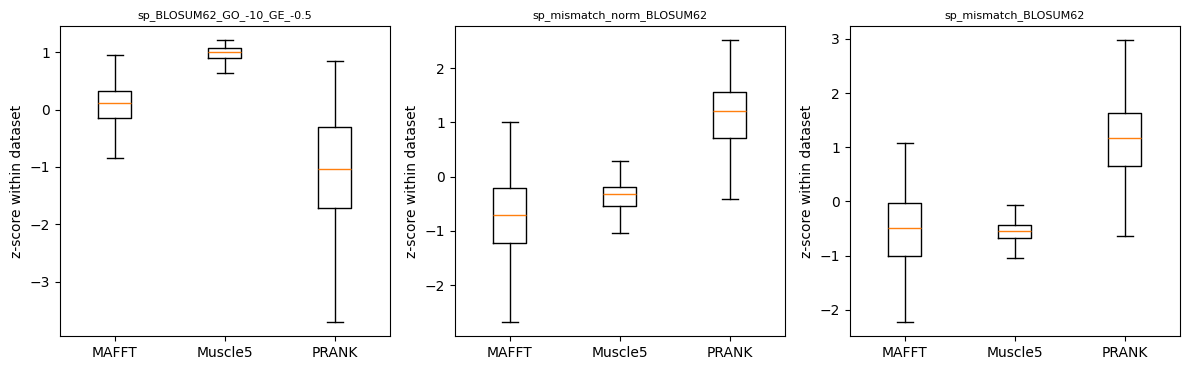


(c) RULER VARIANTS, mean regret

C1 only prank
        model_regret  fixed_all_regret  fixed_mix400_regret  fixed_noprank_regret  fixed_prankonly_regret
family                                                                                                   
126014        0.0235            0.0030               0.0026                0.0018                  0.0236
23410         0.0495            0.0111               0.0110                0.0121                  0.0494
SIM01         0.0084            0.0079               0.0068                0.0125                  0.0054
SIM02         0.0590            0.0133               0.0135                0.0162                  0.0590
SIM03         0.0098            0.0092               0.0092                0.0189                  0.0102
mean: {'model_regret': 0.03, 'fixed_all_regret': 0.0089, 'fixed_mix400_regret': 0.0086, 'fixed_noprank_regret': 0.0123, 'fixed_prankonly_regret': 0.0295}

C2 balanced
        model_regret  fixed_all_regret  fix

In [ ]:
import matplotlib.pyplot as plt
res = pd.read_csv(REV / "revision_perpool.csv"); res["family"] = res["family"].astype(str)

def norm(C, ref_sorted):
    n = ref_sorted.shape[0]; out = np.empty_like(C, dtype=float)
    for j in range(C.shape[1]):
        out[:, j] = (np.searchsorted(ref_sorted[:, j], C[:, j], "left") +
                     np.searchsorted(ref_sorted[:, j], C[:, j], "right")) / 2.0 / n
    return out

# (a) How much do a tool's inputs move when its classmates are only its own tool?
print("(a) INPUT SHIFT: mean change in rank-normalized inputs, own-tool-only vs all three tools")
shift = {}
for fid, df in fam.items():
    X_all = df[FEATS].to_numpy(dtype=float); ref_all = np.sort(X_all, axis=0)
    for s in S:
        Xs = df[df.source == s][FEATS].to_numpy(dtype=float)
        shift[(fid, s)] = np.abs(norm(Xs, np.sort(Xs, axis=0)) - norm(Xs, ref_all)).mean()
sh = pd.Series(shift).unstack().round(3); print(sh.to_string()); print("mean:", sh.mean().round(3).to_dict())

# (b) Which tool's candidates look most different from the other two? (effect size per feature)
print("\n(b) FEATURES that clearly differ (|Cohen's d| > 0.8) between a tool and the other two, out of 153")
big = {}; dvals = []
for fid, df in fam.items():
    for s in S:
        a = df[df.source == s][FEATS]; b = df[df.source != s][FEATS]
        sd = np.sqrt((a.var() + b.var()) / 2).replace(0, np.nan)
        d = ((a.mean() - b.mean()) / sd).fillna(0)
        big[(fid, s)] = int((d.abs() > 0.8).sum())
        if s == "prank": dvals.append(d.rename(fid))
print(pd.Series(big).unstack().to_string())
D = pd.concat(dvals, axis=1); D["mean_abs_d"] = D.abs().mean(axis=1)
top = D.sort_values("mean_abs_d", ascending=False).head(8)
print("\nTop features separating PRANK from the others (d per dataset):"); print(top.round(2).to_string())

# figure: 3 key features by tool (standardized within each dataset)
feats3 = [SOP_SCORE_NAME] + [f for f in top.index if f != SOP_SCORE_NAME][:2]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, f in zip(axes, feats3):
    data = []
    for s in ["mafft", "muscle", "prank"]:
        vals = []
        for fid, df in fam.items():
            z = (df[f] - df[f].mean()) / (df[f].std() or 1)
            vals.append(z[df.source == s])
        data.append(pd.concat(vals))
    ax.boxplot(data, showfliers=False); ax.set_xticks([1, 2, 3], ["MAFFT", "Muscle5", "PRANK"])
    ax.set_title(f, fontsize=8); ax.set_ylabel("z-score within dataset")
plt.tight_layout(); plt.savefig(REV / "fig_feature_distributions.png", dpi=200); plt.show()

# (c) Which property of the ruler matters? (PRANK-only and balanced pools, same 3,500 pools)
print("\n(c) RULER VARIANTS, mean regret")
rc = ["model_regret", "fixed_all_regret", "fixed_mix400_regret", "fixed_noprank_regret", "fixed_prankonly_regret"]
for cond in ["C1 only prank", "C2 balanced"]:
    g = res[res.condition == cond].groupby("family")[rc].mean()
    print(f"\n{cond}"); print(g.round(4).to_string()); print("mean:", g.mean().round(4).to_dict())

# (d) SoP with every gap/matrix setting
print("\n(d) SoP SETTINGS, mean regret over 5 datasets")
sc = [c for c in res.columns if c.startswith("sop::")]
t = res.groupby(["condition", "family"])[sc + ["model_regret", "fixed_all_regret"]].mean().groupby("condition").mean()
t.columns = [c.replace("sop::sp_", "SoP ") for c in t.columns]
print(t.T.round(4).to_string())

In [ ]:
import subprocess
gt = proj / "tools/guidance_compiled.tar.gz"
if not Path("/content/GUIDANCE").exists() and gt.exists():
    subprocess.run(["tar", "-xzf", str(gt), "-C", "/content"])
for name, path in [("sp_alternative", REPO), ("GUIDANCE", Path("/content/GUIDANCE"))]:
    r = subprocess.run(["git", "-c", "safe.directory=*", "-C", str(path), "log", "-1",
                        "--format=commit %H | date %cd | %s"], capture_output=True, text=True)
    print(f"{name}: {r.stdout.strip() or r.stderr.strip()}")

sp_alternative: commit 766a6a61fa798a9e738fb5ca5ca9917755a1fa45 | date Mon May 25 19:14:20 2026 +0300 | clean paths
GUIDANCE: commit 8e40f6c918756b663f1079276d0ac3e6a3d68cb8 | date Tue Nov 28 21:36:45 2023 +0100 | update README
